# 02 — Exploratory Data Analysis & Statistics
## Project: Tech Job Market & Salary Intelligence Platform (India)

**Objective**: Perform statistical exploration and hypothesis testing to answer key business questions regarding tech job demand, compensation structures, experience dynamics, and geographic hubs across India.

---
### Key Business Questions Addressed:
1. **Job Demand**: Which roles and companies are hiring most in India?
2. **Salary Intelligence**: What are the average, median, and spread of salaries per role?
3. **Experience Impact**: How does compensation scale across experience tiers?
4. **Geographic Distribution**: Which Indian tech hubs offer the highest compensation?
5. **Statistical Testing**: Is the salary difference between roles statistically significant (ANOVA)?


In [1]:
# Step 1: Import Libraries & Load Cleaned Data
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 6)

csv_path = "data/processed/cleaned_jobs.csv" if os.path.exists("data/processed/cleaned_jobs.csv") else "../data/processed/cleaned_jobs.csv"
df = pd.read_csv(csv_path)
print(f"Cleaned dataset loaded successfully: {len(df):,} job postings")
df.head(2)


Cleaned dataset loaded successfully: 6,500 job postings
Out[1]: 
           job_id  ...                                  description_clean
0  IND_JOB_000001  ...  We are seeking a talented Applied Data Scienti...
1  IND_JOB_000002  ...  We are seeking a talented Machine Learning Eng...

[2 rows x 44 columns]


,job_id,job_title,role_category,company,company_tier,location_raw,salary_raw,min_salary_lpa_raw,max_salary_lpa_raw,experience_raw,min_exp_years,max_exp_years,employment_type,industry,education_raw,skills_raw,description_raw,posted_date,job_url,source,city,state,location_type,country,experience_min,experience_max,experience_avg,experience_bracket,min_salary_lpa,max_salary_lpa,avg_salary_lpa,is_salary_imputed,min_salary_inr,max_salary_inr,avg_salary_inr,skills,skill_count,year,month,quarter,month_name,year_month,day_of_week,description_clean
0,IND_JOB_000001,Applied Data Scientist,Data Scientist,Wipro,IT_Consulting_Enterprise,Bengaluru / Bangalore,Competitive,NaN,NaN,6 - 9 Yrs,6,9,Full-Time,EdTech & Consumer Internet,"Bachelor's / Master's degree in Statistics, Ma...","Feature Engineering, XGBoost, Machine Learning...",We are seeking a talented Applied Data Scienti...,2026-04-05,https://www.techjobs-india-portal.com/job/000001,Instahyre,Bengaluru,Karnataka,Tier-1 Hub,India,6.0,9.0,7.5,6-9 Yrs (Senior),38.26,55.06,46.66,1,3826000,5506000,4666000,Feature Engineering; XGBoost; Machine Learning...,9,2026,4,Q2,Apr,2026-04,Sunday,We are seeking a talented Applied Data Scienti...
1,IND_JOB_000002,Machine Learning Engineer,AI/ML Engineer,Urban Company,Product_Unicorn,Bengaluru,₹ 67.8 LPA,44.79,90.88,7+ Years,7,9,Full-Time,Analytics & Consulting Services,"Bachelor's / Master's degree in Statistics, Ma...","Computer Vision, AWS SageMaker, TensorFlow, Py...",We are seeking a talented Machine Learning Eng...,2026-01-21,https://www.techjobs-india-portal.com/job/000002,Instahyre,Bengaluru,Karnataka,Tier-1 Hub,India,7.0,9.0,8.0,6-9 Yrs (Senior),44.79,90.88,67.83,0,4479000,9088000,6783000,Computer Vision; Aws Sagemaker; TensorFlow; Py...,8,2026,1,Q1,Jan,2026-01,Wednesday,We are seeking a talented Machine Learning Eng...


### 1. Descriptive Statistics: Salary Across 4 Tech Roles

In [2]:
# Descriptive Summary Table for Salary (INR LPA)
salary_stats = df.groupby("role_category")["avg_salary_lpa"].agg(
    Postings="count",
    Mean="mean",
    Median="median",
    Std_Dev="std",
    Min="min",
    Max="max",
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
).round(2).reset_index()

salary_stats


Out[2]: 
                   role_category  Postings   Mean  ...   Min     Max    IQR
0                 AI/ML Engineer      1084  38.84  ...  9.25  132.34  30.12
1                   Data Analyst      1835  20.40  ...  4.33   68.12  17.70
2                 Data Scientist      1276  32.68  ...  8.00  109.53  29.13
3  Software Development Engineer      2305  34.04  ...  7.50  109.34  29.68

[4 rows x 8 columns]


,role_category,Postings,Mean,Median,Std_Dev,Min,Max,IQR
0,AI/ML Engineer,1084,38.84,33.64,23.22,9.25,132.34,30.12
1,Data Analyst,1835,20.40,16.84,12.26,4.33,68.12,17.70
2,Data Scientist,1276,32.68,26.89,19.30,8.00,109.53,29.13
3,Software Development Engineer,2305,34.04,28.14,20.50,7.50,109.34,29.68


<ipython-input-3-95d05e0db26a>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="role_category", y="avg_salary_lpa", palette="Set2", ax=axes[0])
<ipython-input-3-95d05e0db26a>:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="role_category", y="avg_salary_lpa", palette="Pastel1", inner="quartile", ax=axes[1])


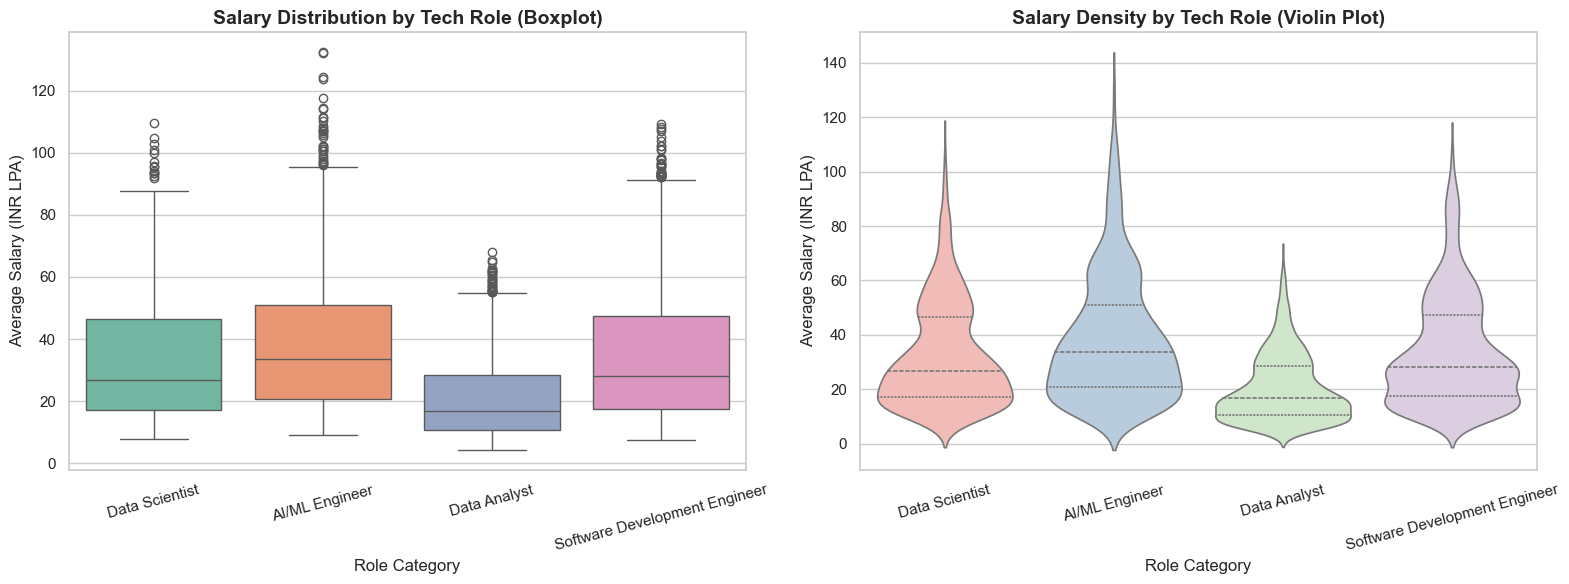

In [3]:
# Visualizing Salary Distributions Across Roles (Box & Violin Plot)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df, x="role_category", y="avg_salary_lpa", palette="Set2", ax=axes[0])
axes[0].set_title("Salary Distribution by Tech Role (Boxplot)", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Role Category")
axes[0].set_ylabel("Average Salary (INR LPA)")
axes[0].tick_params(axis="x", rotation=15)

sns.violinplot(data=df, x="role_category", y="avg_salary_lpa", palette="Pastel1", inner="quartile", ax=axes[1])
axes[1].set_title("Salary Density by Tech Role (Violin Plot)", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Role Category")
axes[1].set_ylabel("Average Salary (INR LPA)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


### 2. Hiring Demand & Geographic Hubs in India

Out[4]: 
        City  Total Postings  Market Share %
0  Bengaluru            2563           39.43
1  Hyderabad            1291           19.86
2  Delhi NCR             947           14.57
3       Pune             803           12.35
4     Mumbai             375            5.77
5    Chennai             332            5.11
6     Remote             189            2.91


<ipython-input-4-003e653d4d74>:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar = sns.barplot(data=city_demand, x="City", y="Total Postings", palette="viridis")


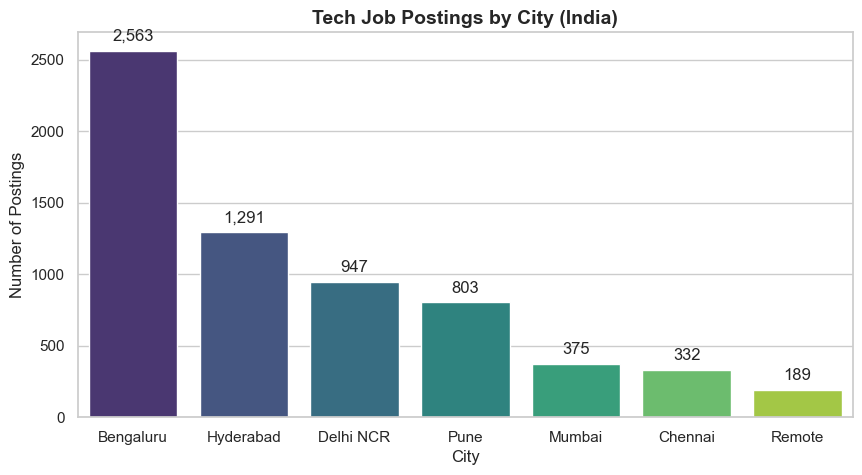

,City,Total Postings,Market Share %
0,Bengaluru,2563,39.43
1,Hyderabad,1291,19.86
2,Delhi NCR,947,14.57
3,Pune,803,12.35
4,Mumbai,375,5.77
5,Chennai,332,5.11
6,Remote,189,2.91


In [4]:
# Job Demand by Indian City
city_demand = df["city"].value_counts().reset_index()
city_demand.columns = ["City", "Total Postings"]
city_demand["Market Share %"] = (city_demand["Total Postings"] / len(df) * 100).round(2)

plt.figure(figsize=(10, 5))
bar = sns.barplot(data=city_demand, x="City", y="Total Postings", palette="viridis")
plt.title("Tech Job Postings by City (India)", fontsize=14, fontweight="bold")
plt.xlabel("City")
plt.ylabel("Number of Postings")
for p in bar.patches:
    bar.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')
plt.show()
city_demand


### 3. Experience vs. Salary Dynamics

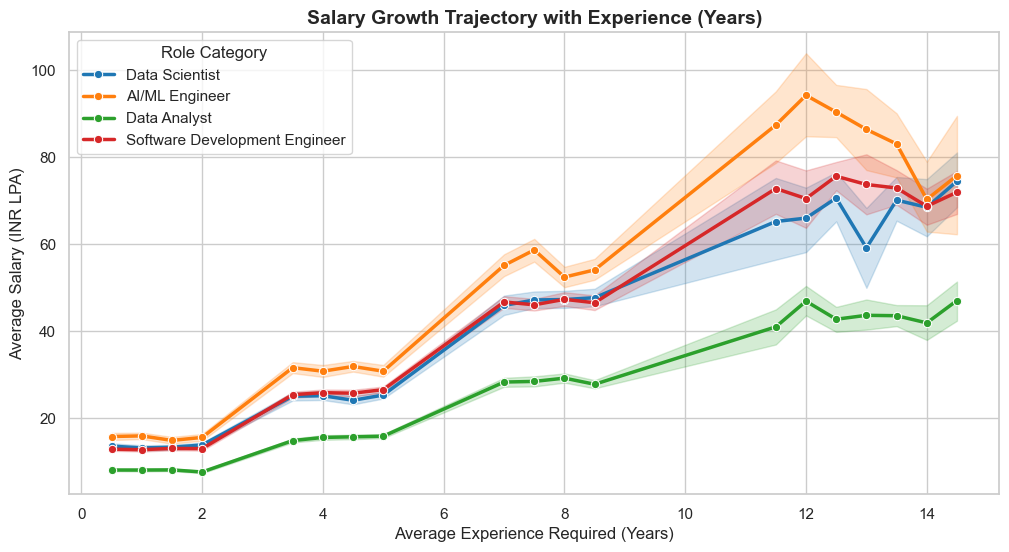

In [5]:
# Experience vs Salary by Role
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df, 
    x="experience_avg", 
    y="avg_salary_lpa", 
    hue="role_category", 
    marker="o", 
    linewidth=2.5,
    palette="tab10"
)
plt.title("Salary Growth Trajectory with Experience (Years)", fontsize=14, fontweight="bold")
plt.xlabel("Average Experience Required (Years)")
plt.ylabel("Average Salary (INR LPA)")
plt.legend(title="Role Category")
plt.show()


### 4. Statistical Hypothesis Testing: One-Way ANOVA on Role Salaries

In [6]:
# Test if salary difference between the 4 roles is statistically significant
roles = df["role_category"].unique()
role_groups = [df[df["role_category"] == r]["avg_salary_lpa"].values for r in roles]

f_stat, p_val = stats.f_oneway(*role_groups)

print(f"ANOVA F-Statistic: {f_stat:.4f}")
print(f"p-value: {p_val:.4e}")

if p_val < 0.05:
    print("Conclusion: Reject Null Hypothesis (H0). There is a statistically significant difference in salaries across tech roles in India.")
else:
    print("Conclusion: Fail to reject Null Hypothesis.")


ANOVA F-Statistic: 279.3507
p-value: 1.4955e-170
Conclusion: Reject Null Hypothesis (H0). There is a statistically significant difference in salaries across tech roles in India.
